# Sleep stage episode comparison between spike types

## Initialization - don't change

In [1]:
import sys
sys.path.append('..')

from pathlib import Path

from tqdm import tqdm

from workflows.run_util.io import collect_paths_from_table
from param_classes.workflows.episode_analysis import EpisodeAnalysisWorkflowParams
from workflows.episode_analysis import run_analysis, run_comparison, create_groups

config = {'data': {}, 'input': {}, 'output': {}, 'params': {}, 'palette': {}}
params = EpisodeAnalysisWorkflowParams()

## Color settings

In [14]:
params.palette = {
    'episode': {
        'awake': '#0000ff',
        'theta': '#ff0000',
        'sw': '#00ff00'
    },
    'spike_type': {
        'AIS-AP': 'celltype',
        'UNKNOWN': '#adadad',
        'RA-AP': '#00ff00'
    },
    'celltype': {
        'PYR_L2-3': '#803300ff',
        'PYR_L4-6': '#502d16ff',
        'RSI_L2-3': '#ff48a3ff',
        'RSI_L4-6': '#800080ff',
        'FSI_L2-3': '#d54500ff',
        'FSI_L4-6': '#7a0000ff'
    }
}

## Data settings

Set raw input dir. You need to give the base path where the group directories can be found.

In [3]:
params.data['raw_data'] = {
    'path': 'C:\\Datasets\\raap\\invivo',
    'extension': 'mat'
}

Set the base path of the directory where csv files containing the spike features and categories can be found.
> It needs to be the same structure as the `raw_data` directory.

In [4]:
params.data['results'] = {
    'path': 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\SpikeFeatures',
    'extension': 'csv'
}

## Input-output settings

Set the Excel table containing the cell attributes, grouping and selector information.

In [5]:
params.input = {
    'mode': 'table',
    'table_path': 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\data_invivo.xlsx',
    'select_rules': [
        {'selected': 1}
    ]
}

Set the output base directory path. All results of this analysis (cellwise aggregated tables, grouped results, figures, statistics) is going to saved there.

In [6]:
params.output.path = 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\SleepStageAnalysis'
params.output.figures.dpi = 100
params.output.figures.as_png = True
params.output.figures.as_svg = True

## Analysis parameters

In [7]:
params.analysis.episodes = ['sw', 'theta', 'awake']
params.analysis.spike_types = ['AIS-AP', 'UNKNOWN', 'RA-AP']
params.analysis.suffix = 'sleep_stages'

## Grouping parameters

In [8]:
params.grouping.aggregation = 'mean'

## Run analysis

Collect input files according to the table.

In [9]:
input_files = collect_paths_from_table(params.data, params.input)
print(f"{len(input_files)} files selected for analysis.")

6 files selected for analysis.


First, perform individual analysis and save the results.

In [10]:
statistics = run_analysis(input_files, params)

100%|██████████| 6/6 [00:00<00:00, 12.66it/s]


Run comparison for each groups.

In [11]:
groups = create_groups(statistics)
run_comparison(groups, params)

Process groups: 100%|██████████| 2/2 [00:00<00:00,  2.98it/s]


## Plot durations per cell

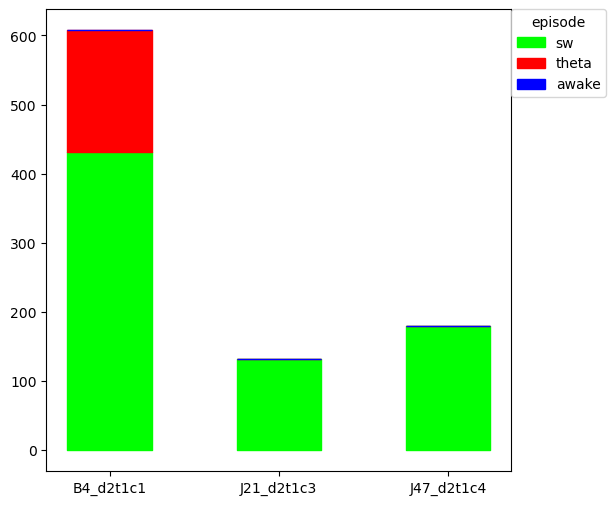

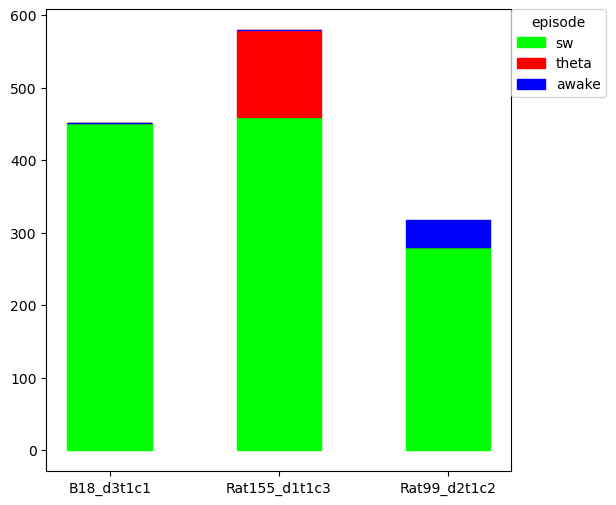

In [15]:
import matplotlib.pyplot as plt
import numpy as np

from workflows.run_util.plotting import CategoricalDistribution, create_stacked_area_chart

for group_name, group_members in groups.items():
    n_members = len(group_members)
    plot_data = []
    for member in group_members:
        durations = np.array([
            member.data[member.data['episode'] == episode]['duration'].sum()
            for episode in params.analysis.episodes
        ])
        plot_data.append((
            member.name,
            CategoricalDistribution(
                durations, params.analysis.episodes, 'episode'
            )
        ))
    fig, ax = plt.subplots(figsize=(n_members * 2, 6))
    create_stacked_area_chart(
        plot_data,
        ax,
        params={
            'palette': [params.palette['episode'][episode] for episode in params.analysis.episodes]
        }
    )
    plt.show()